<a href="https://colab.research.google.com/github/VladyslavNap/EvoAITest/blob/master/DeOldify_Image_%26_Video_Colorizer_GoogleColab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



---


# Correct Runtime Settings

In the "Runtime" menu for the notebook window, select "Change runtime type." Ensure that the following are selected:
* Runtime Type = Python 3
* Hardware Accelerator = GPU


# Git clone and install DeOldify

## i have forked the official repo: [https://github.com/jantic/DeOldify](https://github.com/jantic/DeOldify) and added some test images for ease

In [ ]:
!git clone https://github.com/mmaithani/DeOldify.git DeOldify

Cloning into 'DeOldify'...
remote: Enumerating objects: 2201, done.
remote: Counting objects: 100% (459/459), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 2201 (delta 427), reused 402 (delta 402), pack-reused 1742 (from 1)
Receiving objects: 100% (2201/2201), 72.41 MiB | 21.30 MiB/s, done.
Resolving deltas: 100% (1012/1012), done.


In [1]:
cd DeOldify

/content/DeOldify


# Setup

In [5]:
#NOTE:  This must be the first call in order to work properly!
from deoldify import device
from deoldify.device_id import DeviceId
#choices:  CPU, GPU0...GPU7
device.set(device=DeviceId.GPU0)

import torch

if not torch.cuda.is_available():
    print('GPU not available.')

In [2]:
!pip install -r colab_requirements.txt

In [6]:
!pip install "protobuf<3.21"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 6.8 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.33.6
    Uninstalling protobuf-6.33.6:
      Successfully uninstalled protobuf-6.33.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-dataproc 5.30.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
grain 0.2.18 requires protobuf>=5.28.3, but you have protobuf 3.20.3 which is incompatible.
google-cloud-functions 1.24.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
tensorflow-metadata 1.21.0 requires protobuf>=4.25.2; python_version >= "3.11", but you have protobuf 3.20.3 which is incompatible.
proto-plus 1.29.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
grpcio-status 1.84.0 re

In [8]:
import sys
# Force python to unload any previously loaded protobuf modules so it loads the downgraded version we just installed
for key in list(sys.modules.keys()):
    if 'google.protobuf' in key or 'google/protobuf' in key or key.startswith('protobuf'):
        del sys.modules[key]

import os
os.environ['PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION'] = 'python'

import collections
import collections.abc
# Patch collections to make it compatible with old fastai v1 library
collections.Iterable = collections.abc.Iterable
collections.Mapping = collections.abc.Mapping

import fastai
from deoldify.visualize import *
import warnings
warnings.filterwarnings("ignore", category=UserWarning, message=".*?Your .*? set is empty.*?")

In [9]:
!mkdir 'models'
!wget https://data.deepai.org/deoldify/ColorizeArtistic_gen.pth -O ./models/ColorizeArtistic_gen.pth

--2026-10-19 11:53:38--  https://data.deepai.org/deoldify/ColorizeArtistic_gen.pth
Resolving data.deepai.org (data.deepai.org)... 169.150.249.169, 2400:52e0:1a01::852:1
Connecting to data.deepai.org (data.deepai.org)|169.150.249.169|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 255144681 (243M) [application/octet-stream]
Saving to: ‘./models/ColorizeArtistic_gen.pth’

./models/ColorizeAr 100%[===================>] 243.32M  4.90MB/s    in 49s     

2026-10-19 11:54:27 (4.94 MB/s) - ‘./models/ColorizeArtistic_gen.pth’ saved [255144681/255144681]



In [ ]:
!wget https://media.githubusercontent.com/media/jantic/DeOldify/master/resource_images/watermark.png -O ./resource_images/watermark.png

In [ ]:
colorizer = get_image_colorizer(artistic=True)

# Let's Colorize!!

In [ ]:
source_url = 'https://images.pexels.com/photos/3031397/pexels-photo-3031397.jpeg' #@param {type:"string"}
render_factor = 35  #@param {type: "slider", min: 7, max: 40}
watermarked = True #@param {type:"boolean"}

if source_url is not None and source_url !='':
    image_path = colorizer.plot_transformed_image_from_url(url=source_url, render_factor=render_factor, compare=True, watermarked=watermarked)
    show_image_in_notebook(image_path)
else:
    print('Provide an image url :) ')

## See how well render_factor values perform on the image here

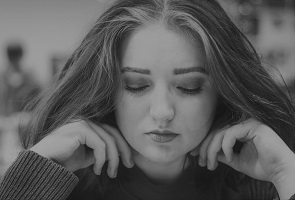

In [ ]:
for i in range(10,40,2):
    colorizer.plot_transformed_image('/content/DeOldify/test_images/vic-P8Fxe0J8Flo-unsplash.jpg', render_factor=i, display_render_factor=True, figsize=(8,8))

## result(colored) image is stored in /DeOldify/test_images/
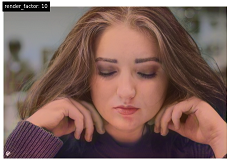

In [ ]:
for i in range(10,40,2):
    colorizer.plot_transformed_image('/content/DeOldify/test_images/mvf78f3j7z961.png', render_factor=i, display_render_factor=True, figsize=(8,8))

In [ ]:
for i in range(10,40,2):
    colorizer.plot_transformed_image('/content/DeOldify/test_images/black-and-white-landscapes.jpg', render_factor=i, display_render_factor=True, figsize=(8,8))

In [ ]:
for i in range(10,40,2):
    colorizer.plot_transformed_image('/content/DeOldify/test_images/68747470733a2f2f692e696d6775722e636f6d2f427430766e6b652e6a7067 (2).jpg', render_factor=i, display_render_factor=True, figsize=(8,8))

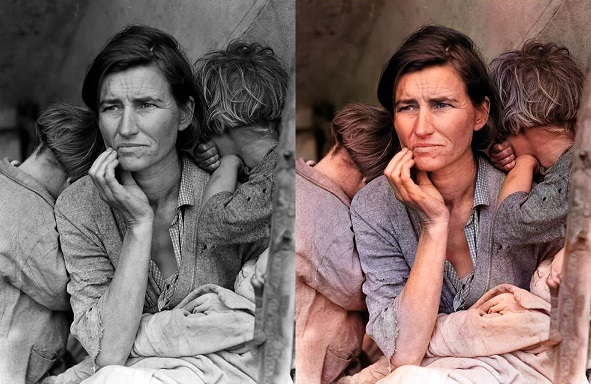

# video colorize

In [10]:
!wget https://data.deepai.org/deoldify/ColorizeVideo_gen.pth -O ./models/ColorizeVideo_gen.pth

--2026-10-19 11:55:00--  https://data.deepai.org/deoldify/ColorizeVideo_gen.pth
Resolving data.deepai.org (data.deepai.org)... 143.244.50.210, 2400:52e0:1a01::1112:1
Connecting to data.deepai.org (data.deepai.org)|143.244.50.210|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 874066230 (834M) [application/octet-stream]
Saving to: ‘./models/ColorizeVideo_gen.pth’

./models/ColorizeVi 100%[===================>] 833.57M  4.90MB/s    in 2m 50s  

2026-10-19 11:57:50 (4.91 MB/s) - ‘./models/ColorizeVideo_gen.pth’ saved [874066230/874066230]



In [13]:
import collections
import collections.abc
import torch

# Patch collections.Sized for fastai compatibility in Python 3.10+
collections.Sized = collections.abc.Sized

# Patch torch.load to default weights_only=False for PyTorch 2.6+ compatibility with fastai v1 weights
_original_torch_load = torch.load
def patched_torch_load(*args, **kwargs):
    if 'weights_only' not in kwargs:
        kwargs['weights_only'] = False
    return _original_torch_load(*args, **kwargs)
torch.load = patched_torch_load

colorizer = get_video_colorizer()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:135: UserWarning: Using 'weights' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Wei

In [14]:
source_path = '/content/Video Project 4.mp4' #@param {type:"string"}
render_factor = 21  #@param {type: "slider", min: 5, max: 40}
watermarked = False #@param {type:"boolean"}

if source_path is not None and source_path !='':
    video_path = colorizer.colorize_from_file_name(source_path, render_factor=render_factor, watermarked=watermarked)
    show_video_in_notebook(video_path)
else:
    print('Provide a local video path and try again.')

<div><progress max="637" value="637"></progress> 100.00% [637/637 1:25:03&lt;00:00]</div>

Video created here: video/result/Video Project 4.mp4


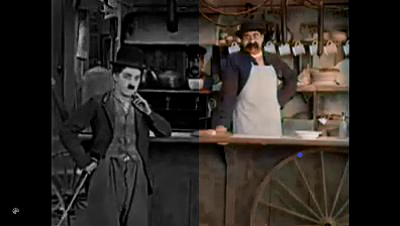

https://youtu.be/jXQYDr2TIhM